# 4. Honest uncertainty, and the rules a molecule must obey

Two separate jobs here.

**Conformal intervals.** A Gaussian process reports a standard deviation, but
that number is only as trustworthy as the kernel and the noise model behind
it. Conformal prediction rescales it against held-out errors so that a stated
90% interval really does contain about 90% of new values.

**Filters and gates.** Three different kinds of rule, which the code keeps
apart on purpose:

| Role | When it applies | Example here |
| --- | --- | --- |
| Search-space filter | before the optimiser sees anything | molecular weight range, QED floor, PAINS removal |
| Objective | during optimisation | potency, solubility, synthesisability |
| Feasibility gate | after prediction | hERG cardiac risk |

Mixing these up is the single easiest way to build a pipeline that looks
correct and quietly optimises the wrong thing.

In [1]:
import sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore"); torch.set_num_threads(2)
sys.path.insert(0, "../src")
from molsdl import chem, conformal, features, models, objectives, plotting

plotting.use_style()
d = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/datasets.pkl", "rb"))
M = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/models.pkl", "rb"))
egfr, esol = d["egfr"], d["esol"]
props = d["props_egfr"]
print("loaded")

loaded


## Why the model's own standard deviation is not enough

A GP's variance comes from the kernel and the fitted noise term. If the
kernel is a poor description of the function, or the noise term is wrong, the
variance is wrong too, and it is wrong in a way that no in-sample check
catches.

Split conformal fixes this with held-out data. Take a calibration set the
model never trained on, compute

    score = |true - predicted| / predicted standard deviation

for every calibration molecule, and take the 90th percentile of those scores.
Call it q. Then the interval

    prediction ± q × predicted standard deviation

covers about 90% of new values. Dividing by the standard deviation is what
keeps the interval wide where the model is unsure and narrow where it is
confident.

In [2]:
fb = M["sol_feature_builder"]
st = M["sol_scaler"]
a, b = M["sol_calib"]
tr, cal, te = M["sol_split"]
X_sol = fb.transform(d["D_esol"])
y_sol = esol.logS.values
base_sol = esol.logS_delaney.values
D0 = fb.n_features
col_mu = st.transform(a * base_sol + b)
col_sd = np.full(len(X_sol), np.std(y_sol[tr] - (a * base_sol[tr] + b)) / st.std_)
X_aug = np.column_stack([X_sol, col_mu, col_sd])

mu_cal, sd_cal = models.gp_predict(M["sol_model"], X_aug[cal])
mu_cal, sd_cal = st.inverse(mu_cal), st.inverse_std(sd_cal)
mu_te, sd_te = models.gp_predict(M["sol_model"], X_aug[te])
mu_te, sd_te = st.inverse(mu_te), st.inverse_std(sd_te)

conf = conformal.SplitConformal(alpha=0.1).fit(y_sol[cal], mu_cal, sd_cal)
report = conf.evaluate(y_sol[te], mu_te, sd_te)
for k, v in report.items():
    print(f"  {k:22s} {v:.3f}" if isinstance(v, float) else f"  {k:22s} {v}")

  alpha                  0.100
  nominal_coverage       0.900
  empirical_coverage     0.965
  mean_width             2.910
  median_width           2.884
  n                      316
  q                      1.243


Coverage above the nominal level means the intervals are conservative: they
are a little wider than they strictly need to be. That is the safe direction
to be wrong in, and it is what small calibration sets tend to produce.

The number to watch is not R². It is this coverage. A model with a mediocre
R² and honest intervals is useful in a decision loop; a model with a good R²
and intervals you cannot believe is not.

### Is the coverage evenly spread?

Overall coverage can be correct while one end of the range is badly served.
Check it in bins.

In [3]:
lo_te, hi_te = conf.interval(mu_te, sd_te)
by_bin = conformal.coverage_by_bin(y_sol[te], lo_te, hi_te, mu_te, n_bins=5)
print(by_bin.to_string(index=False))

                          bin  n  coverage  mean_width
(-10.389999999999999, -3.307] 64  0.890625    3.041013
              (-3.307, -2.22] 63  0.968254    2.964718
              (-2.22, -1.304] 63  1.000000    2.952456
             (-1.304, -0.505] 63  0.984127    2.787256
              (-0.505, 1.662] 63  0.984127    2.801303


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../outputs/figures/04_conformal_coverage.png


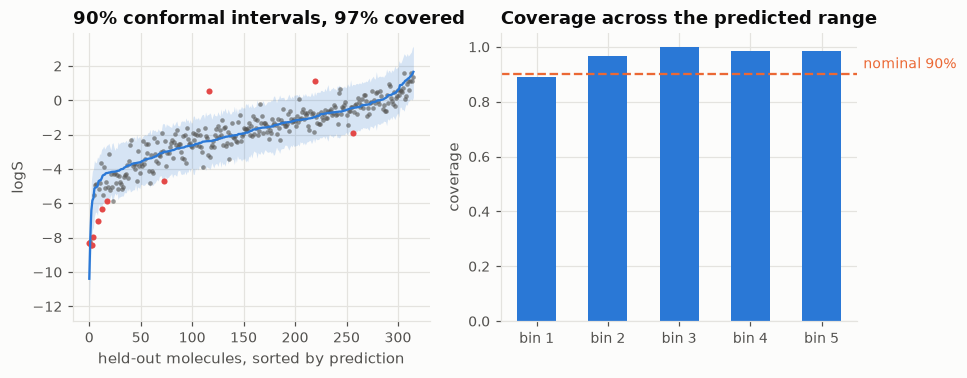

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
order = np.argsort(mu_te)
axes[0].fill_between(np.arange(len(order)), lo_te[order], hi_te[order],
                     color=plotting.C[0], alpha=0.18, linewidth=0)
axes[0].plot(np.arange(len(order)), mu_te[order], color=plotting.C[0], lw=1.5)
inside = (y_sol[te] >= lo_te) & (y_sol[te] <= hi_te)
axes[0].scatter(np.arange(len(order))[inside[order]], y_sol[te][order][inside[order]],
                s=9, color=plotting.INK2, alpha=0.6, linewidths=0)
axes[0].scatter(np.arange(len(order))[~inside[order]], y_sol[te][order][~inside[order]],
                s=16, color=plotting.C[7], linewidths=0)
axes[0].set_xlabel("held-out molecules, sorted by prediction")
axes[0].set_ylabel("logS")
axes[0].set_title(f"90% conformal intervals, {report['empirical_coverage']:.0%} covered")

axes[1].bar(np.arange(len(by_bin)), by_bin["coverage"], width=0.55, color=plotting.C[0])
axes[1].axhline(0.9, color=plotting.C[1], lw=1.5, ls="--")
axes[1].annotate("nominal 90%", xy=(len(by_bin) - 0.5, 0.9), xytext=(4, 4),
                 textcoords="offset points", fontsize=9, color=plotting.C[1])
axes[1].set_xticks(np.arange(len(by_bin)))
axes[1].set_xticklabels([f"bin {i+1}" for i in range(len(by_bin))])
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("coverage")
axes[1].set_title("Coverage across the predicted range")
plotting.save(fig, "04_conformal_coverage")
plt.show()

## Applying the solubility model outside its training chemistry

The solubility model learned on ESOL, which is mostly small, simple organic
compounds. The candidate library is kinase inhibitors: larger, more
elaborate, and chemically unlike anything in ESOL.

This is the everyday situation in drug discovery, and the interval width is
where it shows up. Reporting a point prediction here without an interval would
be the dishonest version of this step.

In [5]:
Xe_desc = fb.transform(d["D_egfr"])
# Delaney's published equation, applied to the library
base_eg = (0.16 - 0.63 * props.logP.values - 0.0062 * props.MW.values
           + 0.066 * props.rotb.values - 0.74 * (props.aromatic_rings.values > 0))
col_mu_e = st.transform(a * base_eg + b)
col_sd_e = np.full(len(Xe_desc), col_sd[0])
Xe_aug = np.column_stack([Xe_desc, col_mu_e, col_sd_e])
mu_e, sd_e = models.gp_predict(M["sol_model"], Xe_aug)
mu_e, sd_e = st.inverse(mu_e), st.inverse_std(sd_e)
lo_e, hi_e = conf.interval(mu_e, sd_e)

print(f"ESOL test set  : predicted sd {sd_te.mean():.3f}, interval width {np.mean(hi_te-lo_te):.2f}")
print(f"EGFR library   : predicted sd {sd_e.mean():.3f}, interval width {np.mean(hi_e-lo_e):.2f}")
print(f"\nspread of predicted sd across the library: "
      f"{sd_e.min():.3f} to {sd_e.max():.3f}")

ESOL test set  : predicted sd 1.170, interval width 2.91
EGFR library   : predicted sd 1.292, interval width 3.21

spread of predicted sd across the library: 0.975 to 1.374


**A limitation worth stating rather than hiding.** The predicted standard
deviation barely varies across the library. With this kernel and this amount
of data, the GP has saturated at its prior uncertainty almost everywhere, so
the conformal interval is close to a constant width rather than a
molecule-by-molecule assessment. It is still calibrated, and it is still
better than a bare point prediction, but it is not yet telling you which
individual molecules are risky.

Fixes, in order of effort: more solubility training data (AqSolDB has about
10,000 compounds), a Tanimoto kernel on fingerprints instead of descriptors,
and a heteroscedastic noise model. Do not write this up as if the intervals
were doing more work than they are.

### Using the lower bound as the objective

Because the library is out of domain, the point prediction is the wrong thing
to optimise. The **conformal lower bound** is the right thing: it asks "how
soluble can I be confident this compound is at worst", which is the question a
project team actually asks before committing to a synthesis.

This also makes the conformal layer load-bearing rather than decorative. It
feeds directly into the optimiser in section 5.

In [6]:
sol_objective = lo_e
print(f"solubility objective (90% lower bound): "
      f"{sol_objective.min():.2f} to {sol_objective.max():.2f} logS")

solubility objective (90% lower bound): -17.41 to -1.46 logS


## Search-space filters

These shrink where the optimiser is allowed to look, before it looks. They
are not predictions and they carry no uncertainty.

* **Molecular weight 150 to 600, logP at most 5.5, at most 5 donors and 10
  acceptors, at most 10 rotatable bonds.** The Lipinski family of rules of
  thumb for compounds that can be taken orally.
* **QED at least 0.35.** A single 0 to 1 drug-likeness score combining those
  properties.
* **No PAINS.** Substructures that interfere with assays and produce
  false positives. A hit containing one is usually an artefact.

In [7]:
keep = objectives.pool_filter(props)
print(f"library: {len(props)} molecules")
print(f"  pass molecular weight range   {int(props.MW.between(150,600).sum())}")
print(f"  pass logP <= 5.5              {int((props.logP <= 5.5).sum())}")
print(f"  pass QED >= 0.35              {int((props.QED >= 0.35).sum())}")
print(f"  free of PAINS                 {int((~props.PAINS).sum())}")
print(f"  pass everything               {int(keep.sum())}")

library: 5531 molecules
  pass molecular weight range   5204
  pass logP <= 5.5              4504
  pass QED >= 0.35              3612
  free of PAINS                 5057
  pass everything               3047


## The feasibility gate: hERG

hERG is a potassium channel in heart muscle. Blocking it lengthens the QT
interval and can cause a fatal arrhythmia, and it has ended drug programmes
at late stage. Every medicinal chemistry team screens for it.

The published pharmacophore picture of a blocker is a greasy molecule with a
basic nitrogen sitting between aromatic rings. The rule here encodes that
shape directly: basic nitrogen, high logP, and three or more aromatic rings.

**It is a surrogate, not a measurement.** It is used here so the gate is
testable with no extra download. `objectives.HergModelGate` takes measured
blocker labels and fits a classifier instead, and that is what belongs in any
write-up. Say which one you used.

In [8]:
herg = objectives.herg_risk_rule(props, logp_cut=4.2, ring_cut=3)
gate_ok = objectives.apply_gates(props, herg_flag=herg, sa_max=6.0)
print(f"hERG rule flags {int(herg.sum())} of {len(props)} ({100*herg.mean():.0f}%)")
print(f"after filters and gates: {int((keep & gate_ok).sum())} molecules remain")

hERG rule flags 2543 of 5531 (46%)
after filters and gates: 2004 molecules remain


Nearly half the library is flagged. That is not the rule misbehaving, it is a
real property of this chemical series: kinase inhibitors tend to be lipophilic
bases with several aromatic rings, which is exactly the hERG liability shape.
A gate that removes half a library is worth knowing about before you spend a
year on it.

  saved ../outputs/figures/04_herg_gate.png


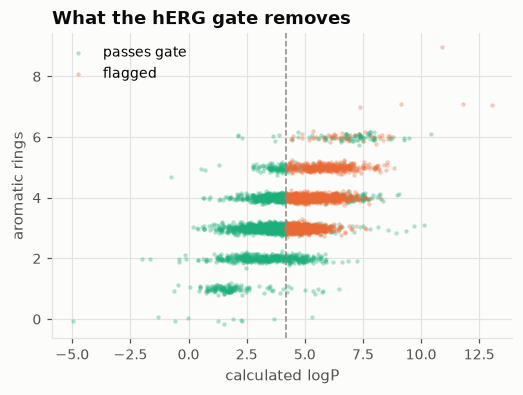

In [9]:
fig, ax = plt.subplots(figsize=(5.4, 3.6))
ok = ~herg
ax.scatter(props.logP[ok], props.aromatic_rings[ok] + np.random.default_rng(0).normal(0, .08, ok.sum()),
           s=8, alpha=0.35, color=plotting.C[2], linewidths=0, label="passes gate")
ax.scatter(props.logP[herg], props.aromatic_rings[herg] + np.random.default_rng(1).normal(0, .08, herg.sum()),
           s=8, alpha=0.35, color=plotting.C[1], linewidths=0, label="flagged")
ax.axvline(4.2, color=plotting.MUTED, lw=1, ls="--")
ax.set_xlabel("calculated logP")
ax.set_ylabel("aromatic rings")
ax.set_title("What the hERG gate removes")
ax.legend(loc="upper left")
plotting.save(fig, "04_herg_gate")
plt.show()

## Building the candidate pool

The optimiser scores a finite library. Which molecules go in it matters as
much as the acquisition function.

Start from everything that passes the filters and the gate, then pick 600 by
**MaxMin**: repeatedly take the molecule least similar to everything picked so
far. That spreads the starting library across chemical space instead of
letting one popular scaffold fill it. It is the molecular version of spreading
your first experiments across the design space rather than clustering them in
one corner.

In [10]:
fp_egfr = np.load("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/fp_egfr.npy")
fp1024 = np.zeros((len(egfr), 1024))
for j in range(fp_egfr.shape[1]):
    fp1024[:, j % 1024] = np.maximum(fp1024[:, j % 1024], fp_egfr[:, j])

idx_ok = np.where(keep & gate_ok)[0]
pick = chem.maxmin_pick(fp1024[idx_ok], 600, seed=0)
pool = idx_ok[pick]

Y_raw = np.column_stack([egfr.pIC50.values[pool], sol_objective[pool], -props.SA.values[pool]])
lo_r, hi_r = Y_raw.min(0), Y_raw.max(0)
Y = (Y_raw - lo_r) / (hi_r - lo_r)
print(f"pool: {len(pool)} molecules")
print(f"  pIC50            {lo_r[0]:.2f} to {hi_r[0]:.2f}")
print(f"  logS lower bound {lo_r[1]:.2f} to {hi_r[1]:.2f}")
print(f"  negative SA      {lo_r[2]:.2f} to {hi_r[2]:.2f}")

pool: 600 molecules
  pIC50            1.60 to 11.00
  logS lower bound -9.03 to -2.77
  negative SA      -5.44 to -1.54


All three objectives are rescaled to 0 to 1 before they are combined. Without
that, hypervolume would be dominated by whichever objective happens to have
the widest numerical range, which is an accident of units rather than a
statement about chemistry.

true Pareto front of this pool: 20 molecules
  saved ../outputs/figures/04_pareto_front.png


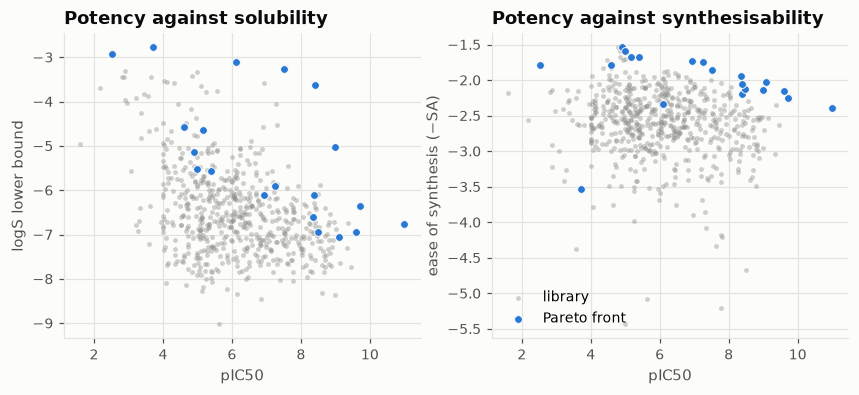

In [11]:
from molsdl import optimise
front = optimise.pareto_mask(Y)
print(f"true Pareto front of this pool: {int(front.sum())} molecules")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))
for ax, (i, j), (xl, yl) in zip(
        axes, [(0, 1), (0, 2)],
        [("pIC50", "logS lower bound"), ("pIC50", "ease of synthesis (−SA)")]):
    ax.scatter(Y_raw[~front, i], Y_raw[~front, j], s=10, alpha=0.4,
               color=plotting.MUTED, linewidths=0, label="library")
    ax.scatter(Y_raw[front, i], Y_raw[front, j], s=26, color=plotting.C[0],
               edgecolors=plotting.SURFACE, linewidths=0.6, label="Pareto front")
    ax.set_xlabel(xl); ax.set_ylabel(yl)
axes[0].set_title("Potency against solubility")
axes[1].set_title("Potency against synthesisability")
axes[1].legend(loc="lower left")
plotting.save(fig, "04_pareto_front")
plt.show()

Those scatter plots are the reason this is a multi-objective problem. The most
potent compounds are not the most soluble, and the easiest to make are not the
most potent. Optimising potency alone walks you into a corner.

In [12]:
pickle.dump({"pool": pool, "Y": Y, "Y_raw": Y_raw, "lo_r": lo_r, "hi_r": hi_r,
             "fp1024": fp1024, "sol_lower": sol_objective, "sol_mu": mu_e,
             "conformal": conf, "conformal_report": report,
             "herg_flag": herg, "keep": keep, "gate_ok": gate_ok},
            open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/pool.pkl", "wb"))
print("saved /Users/arujatiwary/Downloads/molecular-sdl/data/processed/pool.pkl")

saved /Users/arujatiwary/Downloads/molecular-sdl/data/processed/pool.pkl


## What just happened

The uncertainty is now calibrated and its weaknesses are on record. The three
kinds of rule are separated and each is applied where it belongs. And there is
a 600-molecule library with a known Pareto front, which is what makes the next
notebook a measurable experiment rather than a demonstration.